# 01 · Exploration des données

Premier regard sur la photo des prix du 19 octobre 2026 et sur le fichier national des bornes de recharge.

**Questions**
1. Combien coûte chaque carburant, et quelle est la dispersion entre stations ?
2. Les stations d'autoroute sont-elles plus chères, et de combien ?
3. Le prix varie-t-il selon la géographie et la concurrence locale ?
4. Où sont les bornes de recharge, et quelle puissance proposent-elles ?
5. Quelle confiance accorder aux données (fraîcheur, doublons, valeurs manquantes) ?

Les données viennent de la branche `data` du dépôt. La photo du 19 octobre a été réécrite plusieurs fois ce jour-là ; les chiffres ci-dessous correspondent au commit `0daf312` de cette branche : `git fetch origin data && git worktree add data 0daf312`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.neighbors import BallTree

DATA = Path("../data")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
JOUR = "2026-10-19"

pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_width_chars(140)

# Palette de référence (validée daltonisme) et style sobre
BLEU, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

## Chargement

In [2]:
dossier = DATA / "prix" / "instantane" / f"date={JOUR}"
stations = pl.read_parquet(dossier / "stations.parquet")
prix_brut = pl.read_parquet(dossier / "prix.parquet")
bornes = pl.read_parquet(DATA / "irve" / f"bornes_{JOUR}.parquet")
# Un prix qui n'a pas bougé depuis plus de 30 jours ne décrit plus la station (fermée, ou qui ne déclare plus) :
# on ne garde que les prix récents
maintenant = prix_brut["maj"].max()
prix = prix_brut.filter(pl.col("maj") >= maintenant - pl.duration(days=30))
print(f"{stations.height:,} stations · {prix_brut.height:,} prix, dont {prix.height:,} de moins de 30 jours · {bornes.height:,} lignes de bornes")

9,812 stations · 30,504 prix, dont 28,866 de moins de 30 jours · 157,460 lignes de bornes


## 1. Prix par carburant

In [3]:
ORDRE = ["Gazole", "E10", "SP95", "SP98", "E85", "GPLc"]
resume = (
    prix.group_by("carburant")
    .agg(
        stations=pl.len(),
        mediane=pl.col("prix").median(),
        p10=pl.col("prix").quantile(0.10),
        p90=pl.col("prix").quantile(0.90),
        # 1er et 99e centiles plutôt que min et max, qui ne montrent que des erreurs de saisie
        p01=pl.col("prix").quantile(0.01),
        p99=pl.col("prix").quantile(0.99),
    )
    .with_columns(ecart_p90_p10=pl.col("p90") - pl.col("p10"))
    .sort(pl.col("carburant").replace_strict(ORDRE, list(range(len(ORDRE)))))
)
resume

carburant,stations,mediane,p10,p90,p01,p99,ecart_p90_p10
str,u32,f64,f64,f64,f64,f64,f64
"""Gazole""",8612,2.369,2.25,2.459,2.25,2.664,0.209
"""E10""",6632,2.179,1.99,2.269,1.99,2.449,0.279
"""SP95""",2464,2.239,2.169,2.3,1.99,2.405,0.131
"""SP98""",6610,2.289,2.198,2.389,1.99,2.569,0.191
"""E85""",3424,0.879,0.859,0.999,0.799,1.119,0.14
"""GPLc""",1124,1.06,0.989,1.149,0.938,1.259,0.16


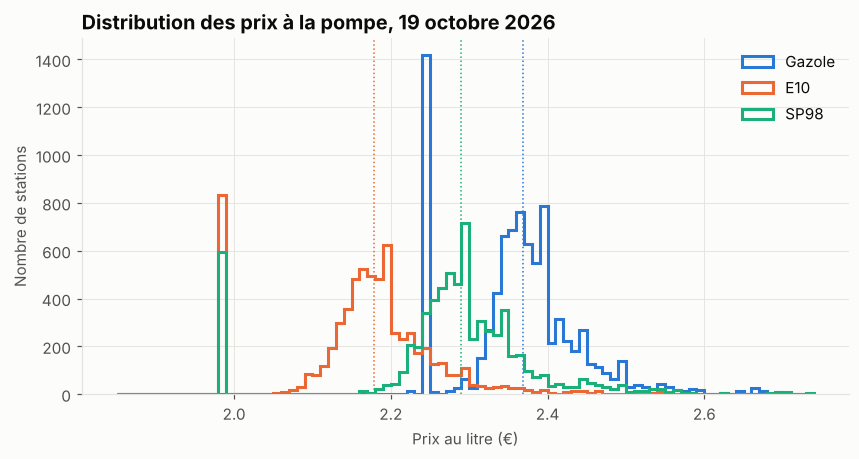

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
principaux = ["Gazole", "E10", "SP98"]
couleurs = [BLEU, ORANGE, AQUA]
bins = np.arange(1.85, 2.75, 0.01)
for carburant, couleur in zip(principaux, couleurs):
    valeurs = prix.filter(carburant=carburant)["prix"].to_numpy()
    ax.hist(valeurs, bins=bins, histtype="step", linewidth=2, color=couleur, label=carburant)
    med = np.median(valeurs)
    ax.axvline(med, color=couleur, linewidth=1, linestyle=":")
ax.set_title("Distribution des prix à la pompe, 19 octobre 2026")
ax.set_xlabel("Prix au litre (€)")
ax.set_ylabel("Nombre de stations")
ax.legend(frameon=False, labelcolor=TEXTE)
sauver(fig, "01_distribution_prix")

Le gazole est plus cher que l'essence (E10, SP98), ce qui est inhabituel en France sur longue période mais cohérent avec les tensions sur le diesel. Entre les 10 % de stations les moins chères et les 10 % les plus chères, l'écart atteint 13 à 28 centimes par litre selon le carburant (21 pour le gazole) : sur un plein de 50 litres, choisir sa station fait gagner 7 à 14 €.

In [5]:
# Les pics de l'histogramme : des prix ronds, identiques partout en France
ronds = {
    "Gazole à 2,25 €": set(prix.filter(carburant="Gazole", prix=2.25)["station_id"]),
    "E10 à 1,99 €": set(prix.filter(carburant="E10", prix=1.99)["station_id"]),
    "SP98 à 1,99 €": set(prix.filter(carburant="SP98", prix=1.99)["station_id"]),
}
gazole_225 = ronds["Gazole à 2,25 €"]
pl.DataFrame([
    {"prix": nom, "stations": len(ids), "dont gazole à 2,25 €": len(ids & gazole_225)}
    for nom, ids in ronds.items()
])

prix,stations,"dont gazole à 2,25 €"
str,i64,i64
"""Gazole à 2,25 €""",1397,1397
"""E10 à 1,99 €""",830,767
"""SP98 à 1,99 €""",596,551


Les pics de l'histogramme correspondent à des prix ronds : 1 397 stations affichent le gazole à exactement 2,25 €, et 767 des 830 stations à 1,99 € pour l'E10 en font partie. Ces stations sont réparties dans toute la France, autoroutes comprises. C'est la signature d'un réseau qui plafonne ses prix au niveau national (hypothèse à confirmer en ajoutant l'enseigne des stations). Pour le modèle de prix, ce sera une variable à part entière : ces stations ne suivent pas la logique locale.

## 2. Autoroute contre route

In [6]:
prix_st = prix.join(stations.select("id", "type_route", "cp", "latitude", "longitude", "services"), left_on="station_id", right_on="id")
autoroute = (
    prix_st.filter(pl.col("carburant").is_in(principaux))
    .group_by("carburant", "type_route")
    .agg(mediane=pl.col("prix").median(), stations=pl.len())
    .pivot(on="type_route", index="carburant", values="mediane")
    .with_columns(surcout=pl.col("autoroute") - pl.col("route"))
)
autoroute

carburant,route,autoroute,surcout
str,f64,f64,f64
"""E10""",2.178,2.279,0.101
"""SP98""",2.289,2.361,0.072
"""Gazole""",2.369,2.458,0.089


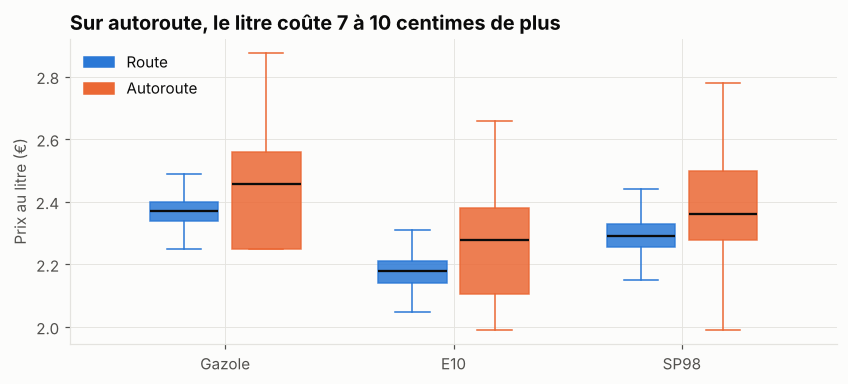

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, carburant in enumerate(principaux):
    for type_route, couleur, decal in [("route", BLEU, -0.18), ("autoroute", ORANGE, 0.18)]:
        valeurs = prix_st.filter(carburant=carburant, type_route=type_route)["prix"].to_numpy()
        bp = ax.boxplot(valeurs, positions=[i + decal], widths=0.3, patch_artist=True,
                        showfliers=False, medianprops={"color": TEXTE, "linewidth": 1.5},
                        boxprops={"facecolor": couleur, "edgecolor": couleur, "alpha": 0.85},
                        whiskerprops={"color": couleur}, capprops={"color": couleur})
ax.set_xticks(range(len(principaux)), principaux)
ax.set_ylabel("Prix au litre (€)")
ax.set_title("Sur autoroute, le litre coûte 7 à 10 centimes de plus")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLEU, label="Route"), Patch(color=ORANGE, label="Autoroute")], frameon=False, labelcolor=TEXTE)
sauver(fig, "02_autoroute")

## 3. Géographie et concurrence locale

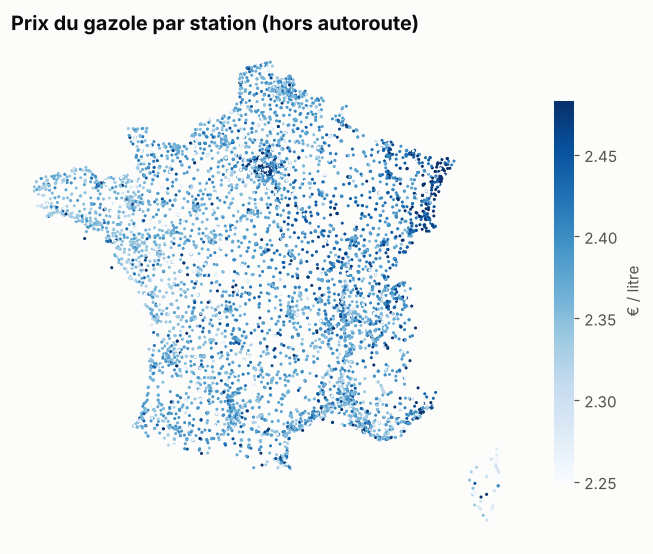

In [8]:
gazole = prix_st.filter(carburant="Gazole", type_route="route").drop_nulls(["latitude", "longitude"])
gazole = gazole.filter(pl.col("latitude").is_between(41, 51.5) & pl.col("longitude").is_between(-5.5, 10))  # métropole

fig, ax = plt.subplots(figsize=(7.5, 7.5))
vmin, vmax = gazole["prix"].quantile(0.05), gazole["prix"].quantile(0.95)
nuage = ax.scatter(gazole["longitude"], gazole["latitude"], c=gazole["prix"], s=4, cmap="Blues",
                   vmin=vmin, vmax=vmax, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(46.5)))
ax.set_axis_off()
ax.set_title("Prix du gazole par station (hors autoroute)")
barre = fig.colorbar(nuage, ax=ax, shrink=0.6, label="€ / litre")
barre.outline.set_visible(False)
sauver(fig, "03_carte_gazole")

In [9]:
# Prix médian du gazole par département (2 premiers chiffres du code postal ; la Corse 20 regroupe 2A et 2B)
departements = (
    gazole.with_columns(dep=pl.col("cp").str.slice(0, 2))
    .group_by("dep")
    .agg(mediane=pl.col("prix").median(), stations=pl.len())
    .filter(pl.col("stations") >= 20)
    .sort("mediane")
)
pl.concat([departements.head(5), departements.tail(5)])

dep,mediane,stations
str,f64,u32
"""20""",2.28,79
"""85""",2.3295,106
"""79""",2.339,57
"""29""",2.339,131
"""44""",2.345,146
"""94""",2.415,71
"""52""",2.419,41
"""57""",2.427,101
"""68""",2.4485,80


In [10]:
# Concurrence : nombre d'autres stations dans un rayon de 5 km
coords = np.radians(gazole.select("latitude", "longitude").to_numpy())
arbre = BallTree(coords, metric="haversine")
voisins = arbre.query_radius(coords, r=5 / 6371, count_only=True) - 1
gazole = gazole.with_columns(concurrents_5km=pl.Series(voisins))

classes = (
    gazole.with_columns(
        classe=pl.when(pl.col("concurrents_5km") == 0).then(pl.lit("0"))
        .when(pl.col("concurrents_5km") <= 2).then(pl.lit("1-2"))
        .when(pl.col("concurrents_5km") <= 5).then(pl.lit("3-5"))
        .when(pl.col("concurrents_5km") <= 10).then(pl.lit("6-10"))
        .otherwise(pl.lit("11+"))
    )
    .group_by("classe")
    .agg(mediane=pl.col("prix").median(), stations=pl.len())
    .sort(pl.col("classe").replace_strict(["0", "1-2", "3-5", "6-10", "11+"], [0, 1, 2, 3, 4]))
)
classes

classe,mediane,stations
str,f64,u32
"""0""",2.379,1476
"""1-2""",2.369,2429
"""3-5""",2.366,1715
"""6-10""",2.359,1305
"""11+""",2.369,1263


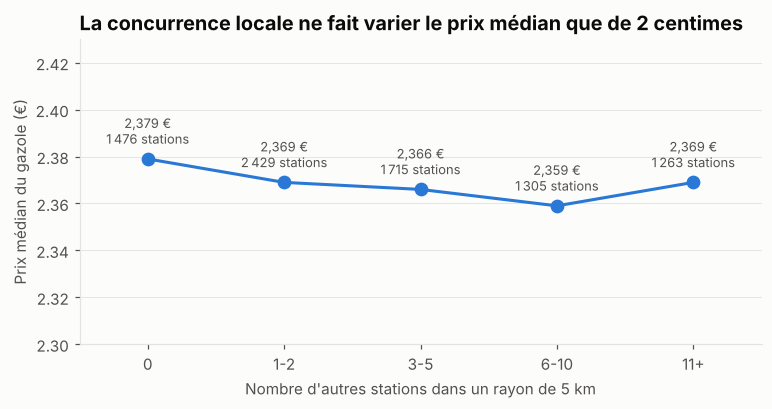

In [11]:
# Points plutôt que barres : l'axe ne part pas de zéro, une barre exagérerait les écarts
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(classes.height)
ax.plot(x, classes["mediane"], color=BLEU, linewidth=2, marker="o", markersize=8)
for xi, (m, n) in enumerate(zip(classes["mediane"], classes["stations"])):
    ax.annotate(f"{m:.3f} €".replace(".", ",") + chr(10) + f"{n:,} stations".replace(",", " "), (xi, m),
                textcoords="offset points", xytext=(0, 10), ha="center", color=TEXTE_2, fontsize=8.5)
ax.set_xticks(x, classes["classe"])
ax.set_ylim(2.30, 2.43)
ax.set_xlim(-0.5, classes.height - 0.5)
ax.set_xlabel("Nombre d'autres stations dans un rayon de 5 km")
ax.set_ylabel("Prix médian du gazole (€)")
ax.set_title("La concurrence locale ne fait varier le prix médian que de 2 centimes")
ax.grid(axis="x", visible=False)
sauver(fig, "04_concurrence")

In [12]:
# Services : les stations avec boutique ou piste poids lourds sont-elles plus chères ?
services_cles = ["Boutique alimentaire", "Piste poids lourds", "Automate CB 24/24", "Lavage automatique", "Restauration à emporter"]
pl.DataFrame([
    {
        "service": s,
        "avec": gazole.filter(pl.col("services").list.contains(s))["prix"].median(),
        "sans": gazole.filter(~pl.col("services").list.contains(s))["prix"].median(),
        "stations_avec": gazole.filter(pl.col("services").list.contains(s)).height,
    }
    for s in services_cles
]).with_columns(ecart=pl.col("avec") - pl.col("sans"))

service,avec,sans,stations_avec,ecart
str,f64,f64,i64,f64
"""Boutique alimentaire""",2.356,2.375,3210,-0.019
"""Piste poids lourds""",2.359,2.376,3265,-0.017
"""Automate CB 24/24""",2.369,2.369,4777,0.0
"""Lavage automatique""",2.359,2.375,2861,-0.016
"""Restauration à emporter""",2.359,2.369,1460,-0.01


Les services ne déplacent le prix médian du gazole que de 1 à 2 centimes, et toujours vers le bas : les stations les mieux équipées (boutique, piste poids lourds, lavage) sont souvent celles des grandes surfaces, qui vendent moins cher. L'automate 24/24, présent dans plus de la moitié des stations, ne montre aucun écart. Ce sont des corrélations, pas des effets causaux : la modélisation (étape 5) les démêlera.

## 4. Bornes de recharge

In [13]:
xy = bornes["coordonneesXY"].str.strip_chars("[] ").str.split(",")
bornes = bornes.with_columns(
    longitude=xy.list.get(0, null_on_oob=True).str.strip_chars().cast(pl.Float64, strict=False),
    latitude=xy.list.get(1, null_on_oob=True).str.strip_chars().cast(pl.Float64, strict=False),
    puissance=pl.col("puissance_nominale").cast(pl.Float64, strict=False),
)
# Un point de recharge peut apparaître plusieurs fois (déclaré par plusieurs sources) : on garde sa déclaration
# la plus récente. Les identifiants hors norme (« Non concerné »...) ne permettent pas de dédoublonner : on garde ces lignes.
id_valide = pl.col("id_pdc_itinerance").str.contains(r"^FR[A-Z0-9]{3}E")
pdc = pl.concat([
    bornes.filter(id_valide).sort("date_maj").unique("id_pdc_itinerance", keep="last"),
    bornes.filter(~id_valide | pl.col("id_pdc_itinerance").is_null()),
])
print(f"{bornes.height:,} lignes, {pdc.height:,} points de recharge, dont {bornes.filter(~id_valide).height:,} sans identifiant valide")

157,460 lignes, 149,551 points de recharge, dont 1,820 sans identifiant valide


In [14]:
# Puissances : 0 veut dire « non renseignée ». Au-delà de 3 000, la puissance est déclarée en watts (3 700, 7 400,
# 22 000) ; entre 1 000 et 3 000, impossible de trancher entre watts et kilowatts : on la laisse non renseignée.
p = pl.col("puissance")
pdc = pdc.with_columns(
    puissance=pl.when((p <= 0) | p.is_between(1000, 3000, closed="left")).then(None)
    .when(p >= 3000).then(p / 1000)
    .otherwise(p)
)
paliers = (
    pdc.with_columns(
        palier=pl.when(pl.col("puissance") < 8).then(pl.lit("< 8 kW (lente)"))
        .when(pl.col("puissance") < 23).then(pl.lit("8-22 kW (accélérée)"))
        .when(pl.col("puissance") < 100).then(pl.lit("23-99 kW (rapide)"))
        .when(pl.col("puissance").is_not_null()).then(pl.lit("≥ 100 kW (ultra-rapide)"))
        .otherwise(pl.lit("non renseignée"))
    )
    .group_by("palier").agg(points=pl.len())
    .with_columns(part=(pl.col("points") / pl.col("points").sum() * 100).round(1))
    .sort("points", descending=True)
)
paliers

palier,points,part
str,u32,f64
"""8-22 kW (accélérée)""",76853,51.4
"""< 8 kW (lente)""",28450,19.0
"""≥ 100 kW (ultra-rapide)""",28119,18.8
"""23-99 kW (rapide)""",13416,9.0
"""non renseignée""",2713,1.8


832 points hors métropole, dont 103 avec longitude = latitude


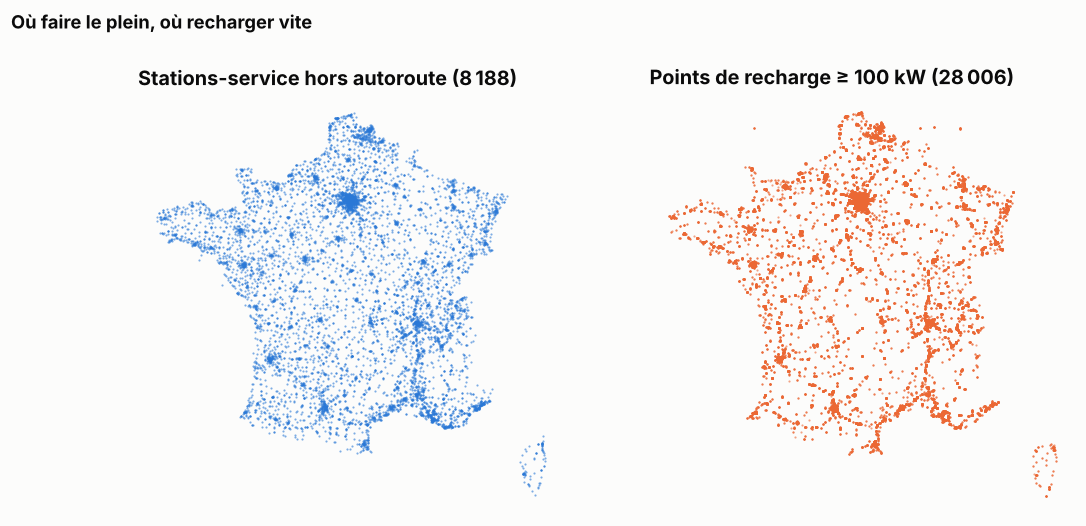

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
# Hors du cadre de la métropole : surtout l'outre-mer (La Réunion, Antilles, Polynésie), et quelques dizaines de points
# dont la longitude a été recopiée sur la latitude
metro = pdc.filter(pl.col("latitude").is_between(41, 51.5) & pl.col("longitude").is_between(-5.5, 10))
print(f"{pdc.height - metro.height:,} points hors métropole, dont {pdc.filter(pl.col('latitude') == pl.col('longitude')).height} avec longitude = latitude")
rapides = metro.filter(pl.col("puissance") >= 100)
for ax, donnees, titre, couleur in [
    (axes[0], gazole, f"Stations-service hors autoroute ({gazole.height:,})".replace(",", " "), BLEU),
    (axes[1], rapides, f"Points de recharge ≥ 100 kW ({rapides.height:,})".replace(",", " "), ORANGE),
]:
    ax.scatter(donnees["longitude"], donnees["latitude"], s=2, color=couleur, linewidths=0, alpha=0.6)
    ax.set_aspect(1 / np.cos(np.radians(46.5)))
    ax.set_axis_off()
    ax.set_title(titre)
fig.suptitle("Où faire le plein, où recharger vite", x=0.02, ha="left", fontweight="bold", color=TEXTE)
sauver(fig, "05_stations_vs_bornes")

In [16]:
# Opérateurs principaux
pdc.group_by("nom_operateur").agg(points=pl.len()).sort("points", descending=True).head(10)

nom_operateur,points
str,u32
"""Bouygues Energies & Services""",15110
"""IZIVIA""",12216
"""Freshmile | FR*FR1""",9488
"""GROUPE INDIGO""",7748
"""Power Dot France""",6611
"""LIDL France""",5562
"""TotalEnergies Charging Service…",4690
"""TESLA France SARL""",4509
"""Greenflux""",4016


## 5. Qualité des données

In [17]:
age = prix_brut.with_columns(age_jours=(maintenant - pl.col("maj")).dt.total_days())
qualite = {
    "prix vieux de plus de 7 jours": age.filter(pl.col("age_jours") > 7).height,
    "prix vieux de plus de 30 jours": age.filter(pl.col("age_jours") > 30).height,
    "stations sans coordonnées": stations.filter(pl.col("latitude").is_null()).height,
    "stations sans aucun prix": stations.join(prix_brut, left_on="id", right_on="station_id", how="anti").height,
    "stations dont tous les prix ont plus de 30 jours": stations.join(prix_brut, left_on="id", right_on="station_id", how="semi")
    .join(prix, left_on="id", right_on="station_id", how="anti").height,
    "lignes IRVE en double (même point de recharge)": bornes.height - pdc.height,
    "points de recharge sans identifiant valide": bornes.filter(~id_valide).height,
    "points de recharge sans code commune": pdc.filter(pl.col("code_insee_commune").is_null()).height,
    "points de recharge sans puissance exploitable": pdc.filter(pl.col("puissance").is_null()).height,
    "points de recharge > 400 kW (suspects)": pdc.filter(pl.col("puissance") > 400).height,
}
pl.DataFrame({"contrôle": list(qualite), "nombre": list(qualite.values())})

contrôle,nombre
str,i64
"""prix vieux de plus de 7 jours""",6942
"""prix vieux de plus de 30 jours""",1561
"""stations sans coordonnées""",0
"""stations sans aucun prix""",620
"""stations dont tous les prix on…",250
"""lignes IRVE en double (même po…",7909
"""points de recharge sans identi…",1820
"""points de recharge sans code c…",62080
"""points de recharge sans puissa…",2713


## À retenir

- La photo du jour suffit pour décrire la géographie des prix, mais pas leur dynamique : c'est l'objet du notebook 02, sur l'historique publié depuis 2007.
- Une part importante des stations (environ 1 500) applique des prix ronds identiques dans toute la France, probablement un plafonnement par une même enseigne.
- L'écart autoroute / route (7 à 10 centimes) et la géographie (plus de 20 centimes entre la Corse et le Bas-Rhin) sont nets ; la concurrence locale, à l'inverse, pèse peu.
- Près d'un prix sur quatre n'a pas été mis à jour depuis plus de 7 jours : pour les analyses temporelles, il faudra pondérer ou filtrer selon la fraîcheur.
- Près de 40 % des points de recharge n'ont pas de code commune : il faudra le recalculer à partir des coordonnées avant de comparer les territoires.
- Le fichier des bornes demande aussi un dédoublonnage (environ 8 000 lignes en double), une correction des puissances déclarées en watts et l'exclusion des puissances à 0.
- Le flux des prix ne donne pas l'enseigne de la station (Total, Leclerc...) : la commande `carburants enseignes` la retrouve dans OpenStreetMap, pour isoler l'effet « grande surface ».